In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("KisanSetu Project is started")

KisanSetu Project is started


In [ ]:
import zipfile, glob

zip_file = glob.glob("*.zip")[0]
zipfile.ZipFile(zip_file).extractall("data")

print("Zip ka naam:", zip_file)
print("CSV files:", glob.glob("data/**/*.csv", recursive=True))

Zip ka naam: archive.zip
CSV files: ['data/Agriculture_price_dataset_unclean_full_more_messy.csv']


In [ ]:
import pandas as pd

df = pd.read_csv("data/Agriculture_price_dataset_unclean_full_more_messy.csv")

print("Rows aur columns:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())
print(df.isnull().sum())

Rows aur columns: (811131, 10)
Columns: ['STATE', 'District Name', 'Market Name', 'Commodity', 'Variety', 'Grade', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price Date']
           STATE District Name        Market Name Commodity           Variety  \
0    Maharashtra        nashik  Lasalgaon(Niphad)     Wheat  Maharashtra 2189   
1    Maharashtra           NaN              Patan    Tomato             Other   
2  uttar pradesh      mainpuri                NaN    Potato               NaN   
3      Rajasthan   chittorgarh                NaN     Wheat             Other   
4      Rajasthan           NaN         Pratapgarh       NaN             Other   

  Grade  Min_Price  Max_Price  Modal_Price Price Date  
0   FAQ        NaN        NaN          NaN   6/6/2023  
1   FAQ     1000.0     1500.0          NaN   6/6/2023  
2   NaN      800.0      820.0          NaN   6/6/2023  
3   FAQ     2040.0     2668.0          NaN        NaN  
4   FAQ      476.0        NaN        617.0   6/6/2023  
STATE  

In [ ]:
print(df["STATE"].str.strip().str.lower().value_counts().head(40))
print(df["Commodity"].str.strip().str.lower().value_counts().head(30))
print(df["Min_Price"].describe())
print(df["Modal_Price"].describe())
print(df["Price Date"].dropna().sample(10, random_state=1).tolist())
print("Duplicate rows:", df.duplicated().sum())

STATE
uttar pradesh        154793
tamilnadu             54818
haryana               52261
madhya pradesh        46197
west bengal           44544
maharashtra           42768
nan                   38438
kerala                37559
punjab                37010
rajasthan             29444
gujarat               21904
himachal pradesh      18787
orissa                16958
karnataka             11772
bihar                 10383
andhra pradesh         7968
jammu & kashmir        4414
assam                  3359
delhi                  3089
nagaland               2506
chattisgarh            2138
chhattisgarh           1843
manipur                1082
chandigarh              809
jammu and kashmir       765
meghalaya               651
uttrakhand               38
tamil nadu               18
tripura                   6
gao                       4
Name: count, dtype: int64
Commodity
potato    270231
onion     246072
wheat      63481
tomato     21970
rice        6400
Name: count, dtype: int64
count  

In [ ]:
import pandas as pd
import numpy as np

# 1. Columns ke naam chhote aur simple karo
df.columns = ["state", "district", "market", "commodity", "variety", "grade",
              "min_price", "max_price", "modal_price", "date"]
print("Shuru mein rows:", len(df))

# 2. Text saaf karo: extra space hatao, chhote akshar, 'nan' ko khali maano
for col in ["state", "district", "market", "commodity", "variety", "grade"]:
    df[col] = df[col].astype(str).str.strip().str.lower()
    df[col] = df[col].replace({"nan": np.nan, "": np.nan})

# 3. State ke galat spelling theek karo
state_fix = {"tamilnadu": "tamil nadu", "chattisgarh": "chhattisgarh",
             "uttrakhand": "uttarakhand", "orissa": "odisha",
             "jammu & kashmir": "jammu and kashmir"}
df["state"] = df["state"].replace(state_fix)

# 4. Jin rows mein zaroori cheez khali hai, unhe hatao
df = df.dropna(subset=["state", "district", "commodity", "date",
                       "min_price", "max_price", "modal_price"])
print("Khali values hatane ke baad:", len(df))

# 5. Date ko sahi format mein badlo
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y", errors="coerce")
df = df.dropna(subset=["date"])
print("Date theek karne ke baad:", len(df))

# 6. Galat bhav hatao (0 ya bahut bada), aur min <= modal <= max rakho
df = df[(df["min_price"] >= 100) & (df["max_price"] <= 20000) & (df["modal_price"] >= 100)]
df = df[(df["min_price"] <= df["modal_price"]) & (df["modal_price"] <= df["max_price"])]
print("Galat bhav hatane ke baad:", len(df))

# 7. Bahut kam rows wale state (jaise junk 'gao') hatao
counts = df["state"].value_counts()
df = df[df["state"].isin(counts[counts >= 100].index)]

# 8. Repeat rows hatao
df = df.drop_duplicates()

# 9. Year aur month nikalo, naam sundar karo
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
for col in ["state", "district", "commodity"]:
    df[col] = df[col].str.title()

# 10. Saaf data save karo
df.to_csv("clean_data.csv", index=False)

print("---- Saaf data ----")
print("Final rows:", len(df))
print("States:", df["state"].nunique(), "| Districts:", df["district"].nunique())
print("Fasal:", df["commodity"].unique().tolist())
print("Saal:", df["year"].min(), "se", df["year"].max())
print(df.head())

Shuru mein rows: 811131
Khali values hatane ke baad: 108236
Date theek karne ke baad: 108236
Galat bhav hatane ke baad: 107630
---- Saaf data ----
Final rows: 107273
States: 23 | Districts: 357
Fasal: ['Wheat', 'Potato', 'Tomato', 'Onion', 'Rice']
Saal: 2023 se 2025
        state      district                  market commodity variety grade  \
11  Rajasthan    Pratapgarh              pratapgarh     Wheat    dara   NaN   
13    Haryana       Panipat                 panipat    Potato   other   faq   
24    Gujarat         Anand  khambhat(grain market)     Wheat   other   faq   
40    Gujarat         Surat                     NaN    Potato   other   faq   
43    Haryana  Yamuna Nagar                  radaur    Tomato   other   faq   

    min_price  max_price  modal_price       date  year  month  
11     2250.0     2450.0       2300.0 2023-06-06  2023      6  
13      600.0     1000.0        800.0 2023-06-06  2023      6  
24     2125.0     2350.0       2225.0 2023-06-06  2023      6  
40

In [ ]:
import pandas as pd
import joblib
import json
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Mahine-wise average nikalo (model ke liye saaf aur chhota data)
monthly = (df.groupby(["state", "district", "commodity", "year", "month"], as_index=False)
             [["min_price", "max_price", "modal_price"]].mean())
print("Mahine-wise rows:", len(monthly))

# 2. Input (X) aur output (y)
X = monthly[["state", "district", "commodity", "month", "year"]]
y = monthly[["min_price", "max_price", "modal_price"]]

# 3. 2023-2024 se seekho, 2025 par test karo
train = monthly["year"] <= 2024
X_train, X_test = X[train], X[~train]
y_train, y_test = y[train], y[~train]
print("Train rows:", len(X_train), "| Test rows:", len(X_test))

# 4. Text ko numbers mein badlo, phir Random Forest model
prep = ColumnTransformer(
    [("text_to_numbers", OneHotEncoder(handle_unknown="ignore"), ["state", "district", "commodity"])],
    remainder="passthrough",
)
model = Pipeline([
    ("prep", prep),
    ("rf", RandomForestRegressor(n_estimators=50, min_samples_leaf=10, random_state=42, n_jobs=-1)),
])

# 5. Train karo
model.fit(X_train, y_train)

# 6. Accuracy (report mein ye numbers likhna)
pred = model.predict(X_test)
print("MAE (average galti, Rs/quintal):", round(mean_absolute_error(y_test, pred), 1))
print("R2 score (1 ke jitna paas, utna accha):", round(r2_score(y_test, pred), 3))

# 7. Poore data par dobara train karke save karo
model.fit(X, y)
joblib.dump(model, "price_model.pkl", compress=3)

# 8. Dropdown ke liye state -> districts ki list
locations = {s: sorted(g["district"].unique().tolist()) for s, g in monthly.groupby("state")}
with open("locations.json", "w") as f:
    json.dump({"locations": locations, "crops": sorted(monthly["commodity"].unique().tolist())}, f, indent=2)


# 9. Backend wale ke liye function
def predict_price(state, district, crop, month, year):
    row = pd.DataFrame([{"state": state, "district": district, "commodity": crop, "month": month, "year": year}])
    mn, mx, modal = model.predict(row)[0]
    return {"min_price": round(mn), "max_price": round(mx), "modal_price": round(modal)}


first = monthly.iloc[0]
print("Test:", first["state"], first["district"], first["commodity"], "->",
      predict_price(first["state"], first["district"], first["commodity"], 11, 2025))
print("Model aur locations.json ban gayi")

Mahine-wise rows: 13549
Train rows: 10766 | Test rows: 2783
MAE (average galti, Rs/quintal): 617.3
R2 score (1 ke jitna paas, utna accha): 0.461
Test: Andhra Pradesh Adilabad Onion -> {'min_price': 3532, 'max_price': 4563, 'modal_price': 4177}
Model aur locations.json ban gayi


In [ ]:
from google.colab import files

files.download("price_model.pkl")
files.download("locations.json")
files.download("clean_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%%writefile app.py
import json
import os
from datetime import datetime

import joblib
import pandas as pd
from flask import Flask, jsonify, request

app = Flask(__name__)

try:
    from flask_cors import CORS
    CORS(app)
except ImportError:
    pass

BASE = os.path.dirname(os.path.abspath(__file__))
model = joblib.load(os.path.join(BASE, "price_model.pkl"))
with open(os.path.join(BASE, "locations.json")) as f:
    data = json.load(f)

locations = data["locations"]
crops = data["crops"]


@app.route("/")
def home():
    return jsonify({"message": "Kisan Setu price API chal rahi hai"})


@app.route("/locations")
def get_locations():
    return jsonify(data)


@app.route("/predict", methods=["POST"])
def predict():
    body = request.get_json(silent=True) or {}

    state = body.get("state")
    district = body.get("district")
    crop = body.get("crop")
    now = datetime.now()
    month = body.get("month", now.month)
    year = body.get("year", now.year)

    if not state or not district or not crop:
        return jsonify({"error": "state, district aur crop zaroori hain"}), 400
    if state not in locations:
        return jsonify({"error": "Ye state list mein nahi hai: " + str(state)}), 400
    if district not in locations[state]:
        return jsonify({"error": "Ye district is state mein nahi hai: " + str(district)}), 400
    if crop not in crops:
        return jsonify({"error": "Ye fasal list mein nahi hai: " + str(crop)}), 400
    try:
        month = int(month)
        year = int(year)
    except (TypeError, ValueError):
        return jsonify({"error": "month aur year number hone chahiye"}), 400
    if not 1 <= month <= 12:
        return jsonify({"error": "month 1 se 12 ke beech hona chahiye"}), 400

    row = pd.DataFrame([{"state": state, "district": district, "commodity": crop,
                         "month": month, "year": year}])
    mn, mx, modal = model.predict(row)[0]

    return jsonify({
        "state": state, "district": district, "crop": crop,
        "month": month, "year": year,
        "min_price": round(float(mn)),
        "max_price": round(float(mx)),
        "modal_price": round(float(modal)),
        "unit": "Rs per quintal",
    })


if __name__ == "__main__":
    app.run(debug=True)

Writing app.py


In [ ]:
import json
from app import app

c = app.test_client()
loc = json.load(open("locations.json"))
state = list(loc["locations"])[0]
district = loc["locations"][state][0]

r = c.post("/predict", json={"state": state, "district": district, "crop": "Onion"})
print(r.get_json())

{'crop': 'Onion', 'district': 'Adilabad', 'max_price': 4563, 'min_price': 3532, 'modal_price': 4177, 'month': 11, 'state': 'Andhra Pradesh', 'unit': 'Rs per quintal', 'year': 2026}


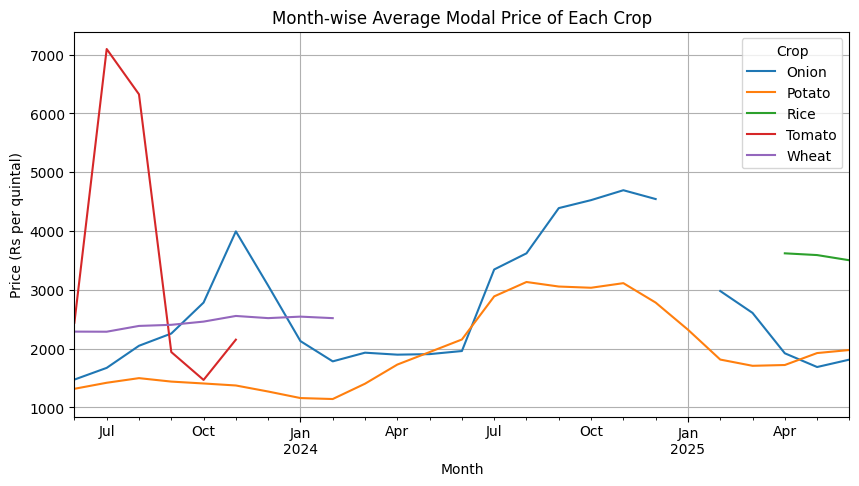

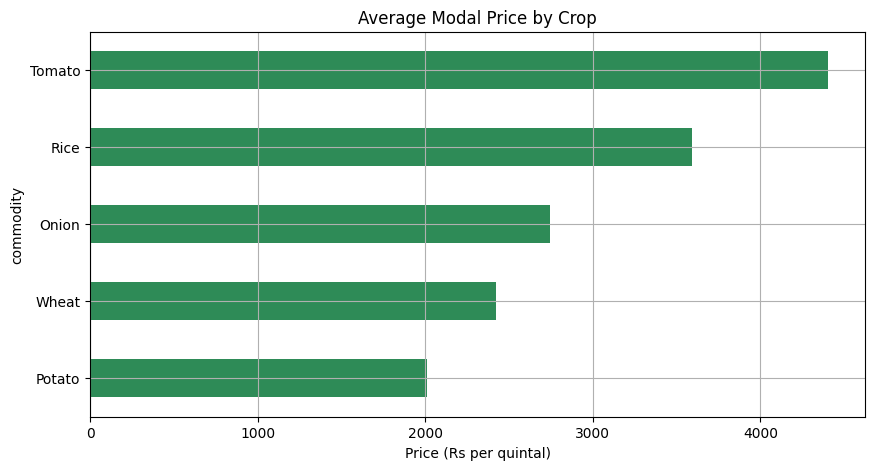

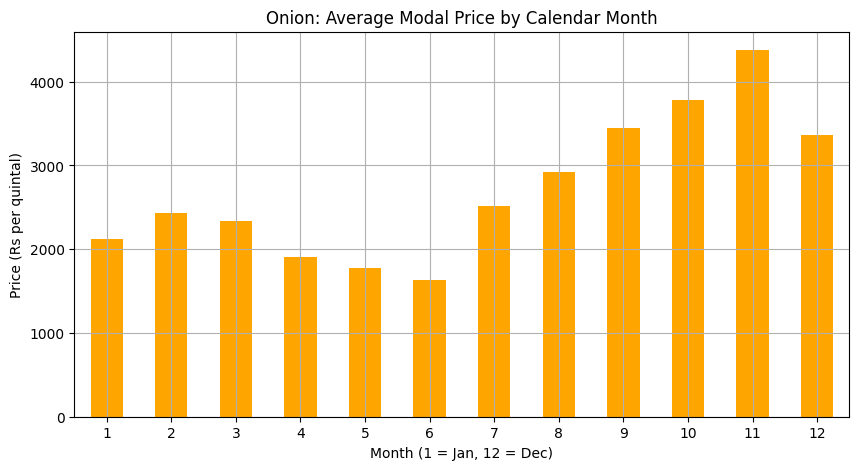

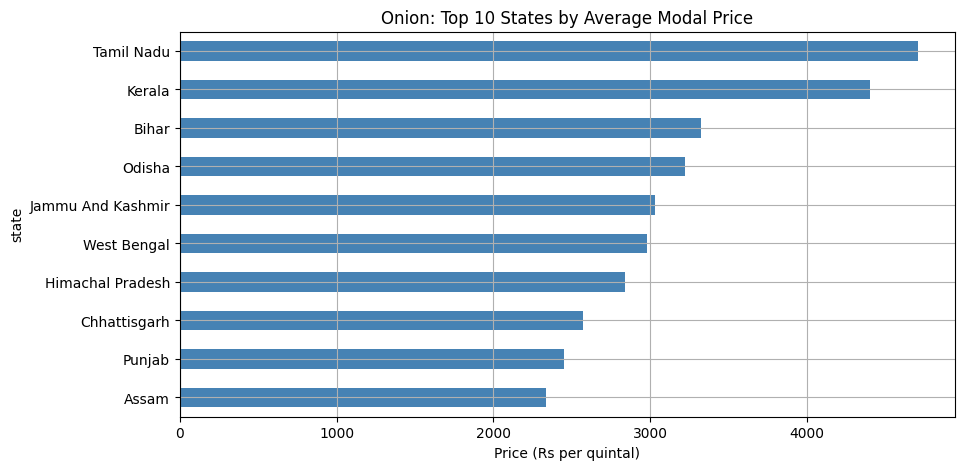

INSIGHTS:
1. Sabse mehngi fasal: Tomato | Rs 4404
2. Sabse sasti fasal: Potato | Rs 2008
3. Pyaaz sabse mehnga mahina: 11 | Rs 4378
4. Pyaaz sabse sasta mahina: 6 | Rs 1635
5. Pyaaz ka sabse mehnga state: Tamil Nadu | Rs 4709
6. Total rows: 107273 | States: 23 | Districts: 357


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

# Mahine ka label banao (jaise 2023-06)
df["year_month"] = df["date"].dt.to_period("M").dt.to_timestamp()

# ---- Graph 1: Har fasal ka mahine-wise average bhav ----
trend = df.groupby(["year_month", "commodity"])["modal_price"].mean().unstack()
trend.plot()
plt.title("Month-wise Average Modal Price of Each Crop")
plt.xlabel("Month")
plt.ylabel("Price (Rs per quintal)")
plt.legend(title="Crop")
plt.savefig("graph1_monthly_trend.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# ---- Graph 2: Kaunsi fasal ka bhav sabse zyada ----
crop_avg = df.groupby("commodity")["modal_price"].mean().sort_values()
crop_avg.plot(kind="barh", color="seagreen")
plt.title("Average Modal Price by Crop")
plt.xlabel("Price (Rs per quintal)")
plt.savefig("graph2_crop_average.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# ---- Graph 3: Pyaaz ka bhav kaun se mahine mein zyada/kam (season) ----
onion = df[df["commodity"] == "Onion"]
by_month = onion.groupby("month")["modal_price"].mean()
by_month.plot(kind="bar", color="orange")
plt.title("Onion: Average Modal Price by Calendar Month")
plt.xlabel("Month (1 = Jan, 12 = Dec)")
plt.ylabel("Price (Rs per quintal)")
plt.xticks(rotation=0)
plt.savefig("graph3_onion_by_month.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# ---- Graph 4: Pyaaz ke sabse mehnge 10 state ----
state_counts = onion["state"].value_counts()
good_states = state_counts[state_counts >= 200].index
top_states = (onion[onion["state"].isin(good_states)]
              .groupby("state")["modal_price"].mean().sort_values().tail(10))
top_states.plot(kind="barh", color="steelblue")
plt.title("Onion: Top 10 States by Average Modal Price")
plt.xlabel("Price (Rs per quintal)")
plt.savefig("graph4_onion_top_states.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close()

# ---- Insights (report mein likhne ke liye) ----
print("INSIGHTS:")
print("1. Sabse mehngi fasal:", crop_avg.index[-1], "| Rs", round(crop_avg.iloc[-1]))
print("2. Sabse sasti fasal:", crop_avg.index[0], "| Rs", round(crop_avg.iloc[0]))
print("3. Pyaaz sabse mehnga mahina:", by_month.idxmax(), "| Rs", round(by_month.max()))
print("4. Pyaaz sabse sasta mahina:", by_month.idxmin(), "| Rs", round(by_month.min()))
print("5. Pyaaz ka sabse mehnga state:", top_states.index[-1], "| Rs", round(top_states.iloc[-1]))
print("6. Total rows:", len(df), "| States:", df["state"].nunique(), "| Districts:", df["district"].nunique())


# ---- Saari images ek zip mein download ----
import zipfile, glob
from google.colab import files

with zipfile.ZipFile("graphs.zip", "w") as z:
    for p in sorted(glob.glob("graph*.png")):
        z.write(p)
files.download("graphs.zip")